# Soft Segmentation Tutorial (SMURF-full)

This notebook demonstrates the SMURF-full workflow on the 10x FFPE mouse brain Visium HD dataset. SMURF-full uses the same overall soft-segmentation pipeline as SMURF-lite, but adds a deep-learning refinement for shared spots involving cells of the same type. A GPU is strongly recommended for practical runtimes.

### Dataset Information

Access the dataset here: [Visium HD CytAssist Gene Expression Libraries of Mouse Brain](https://www.10xgenomics.com/datasets/visium-hd-cytassist-gene-expression-libraries-of-mouse-brain-he)

### Important Downloads

To download the necessary files, run the following commands:

```python

# Download data from 10x
!mkdir -p "smurf_example_data"
!wget -P smurf_example_data https://cf.10xgenomics.com/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_tissue_image.tif
!wget -P smurf_example_data https://cf.10xgenomics.com/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_binned_outputs.tar.gz
!tar -xzvf smurf_example_data/Visium_HD_Mouse_Brain_binned_outputs.tar.gz -C smurf_example_data

# Download our nuclei segmentation results if needed
!curl -L -o smurf_example_data/segmentation_final.npy.gz https://github.com/The-Mitra-Lab/SMURF/raw/main/data/segmentation_final.npy.gz
!gunzip smurf_example_data/segmentation_final.npy.gz

```

If you use the same cell segmentation method as introduced, you may skip the first part until the section labeled [Start here](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/Tutorial_Mousebrain_full.html#Start-here-optional-shortcut).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
import anndata

import smurf as su

import pickle
import copy
import gzip

> **Note on software versions**
>
> This tutorial was developed and tested with the exact package versions listed below.  
> Using these versions should reproduce the results exactly.  
> Newer releases may introduce subtle differences.  
> If you encounter any issues, please open an issue on our GitHub repository and we’ll respond as soon as possible. Thanks!

| Package        | Version        |
|----------------|----------------|
| numpy          | 1.26.4         |
| pandas         | 1.5.3          |
| tqdm           | 4.66.2         |
| scanpy         | 1.10.0         |
| scipy          | 1.12.0         |
| matplotlib     | 3.8.3          |
| numba          | 0.59.0         |
| scikit-learn   | 1.4.1.post1    |
| Pillow         | 10.2.0         |
| anndata        | 0.10.6         |
| h5py           | 3.10.0         |
| pyarrow        | 16.1.0         |
| igraph         | 0.11.5         |
| torch          | 2.2.1+cu12     |


Here, we define your data path and saving path. Ensure that your data path includes the complete HE or DAPI image and a folder containing `square_002um` data. Specifically, you will need `tissue_positions.parquet` and `filtered_feature_bc_matrix`.


In [2]:
import os

data_path = 'smurf_example_data/'
save_path = 'results_example_mousebrain_full/'

# Check if the directory exists
if not os.path.exists(save_path):
    # If it doesn't exist, create it
    os.makedirs(save_path)


We start building our So (spatial object). The input should be your `tissue_positions.parquet` in `'square_002um/spatial'`, the final full image, and the format of your experiment (either `'HE'` or `'DAPI'`).

In [3]:
so = su.prepare_dataframe_image(data_path+'binned_outputs/square_002um/spatial/tissue_positions.parquet',
                                data_path+'Visium_HD_Mouse_Brain_tissue_image.tif',
                               'HE')

Please use your own tools to perform cell segmentation on `so.image_temp()` (the area covered by Visium HD in the original image). Set all background pixels to `0` and assign each cell a unique integer cell ID. `segmentation_final` should be a NumPy array with the same shape as `so.image_temp()`.

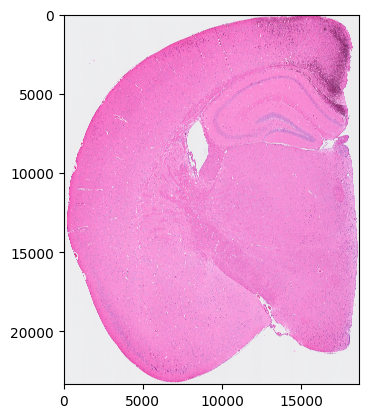

In [4]:
plt.imshow(so.image_temp())
plt.show()
plt.close()

Please save the image for segmentation now

In [5]:
with gzip.GzipFile(data_path + 'image_to_segmentation.npy.gz', 'w') as f:
    np.save(f, so.image_temp())

Assuming we now have the final segmentation results, let's proceed to read them. You can always use the provided example results to try out the tutorial.

In [6]:
so.segmentation_final = np.load(data_path+'segmentation_final.npy')

Now, we start generating cell and spot information to prepare for the analysis.


In [7]:
so.generate_cell_spots_information()

Generating cells information.


100%|██████████| 23340/23340 [01:08<00:00, 338.81it/s]


Generating spots information.


100%|██████████| 23340/23340 [02:57<00:00, 131.62it/s]


Filtering cells
We have 57300 nuclei in total.
Creating NN network


Visualize the nuclei segmentation results overlaid on the original HE or DAPI image. Ensure that the results are meaningful and that the segmented nuclei accurately align with the original image.

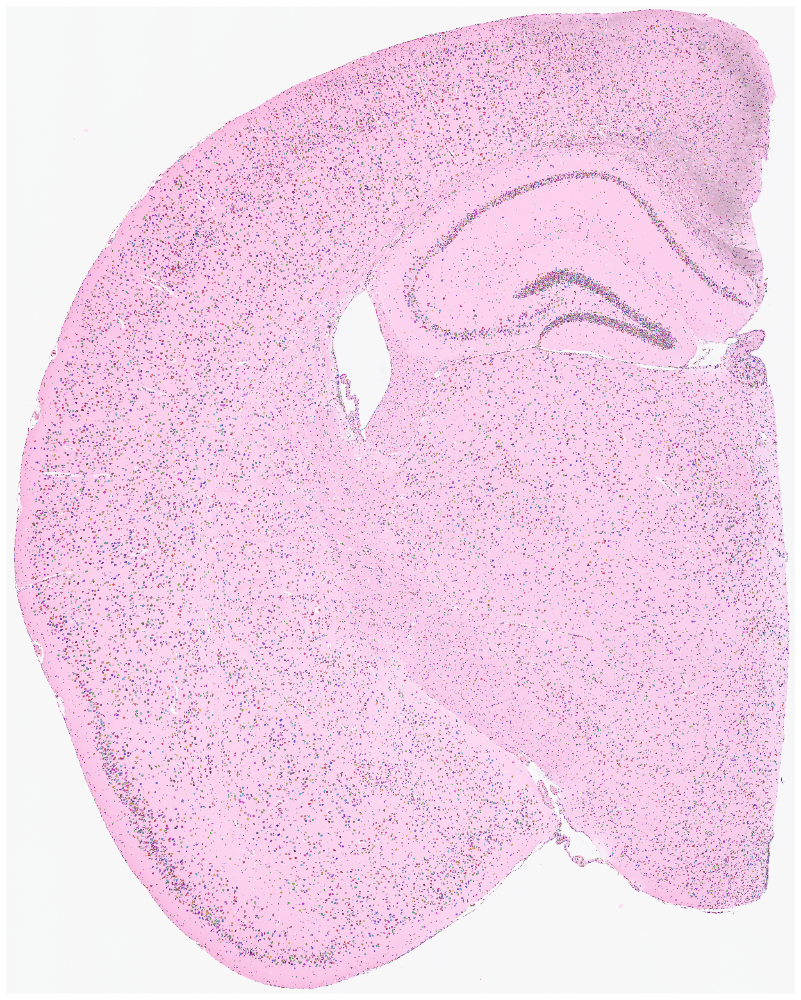

In [8]:
su.plot_results(so.image_temp(), so.segmentation_final )

## Start here (optional shortcut)
Use this section only if you already saved a prepared `so.pkl` object from a previous run, or downloaded a prepared example object. Otherwise, continue from the beginning of the notebook.


```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
import anndata

import smurf as su

import pickle
import copy


with open(save_path + 'so.pkl', 'rb') as file:
    so = pickle.load(file)

```


Load `adata` from the original 2 μm results.

In [9]:
# load adata from original 2um results

adata = sc.read_10x_mtx(data_path +'binned_outputs/square_002um/filtered_feature_bc_matrix')
adata = copy.deepcopy(adata[so.df[so.df.in_tissue == 1]['barcode']])
adata.obs

""
s_002um_02448_01644-1
s_002um_00700_02130-1
s_002um_00305_01021-1
s_002um_02703_00756-1
s_002um_02278_00850-1
...
s_002um_02189_01783-1
s_002um_01609_01578-1
s_002um_00456_02202-1
s_002um_00292_01011-1


In [10]:
sc.pp.filter_genes(adata, min_counts=1000) 

Here, we begin by generating the `nuclei*genes` matrix. The result will be stored in `so.final_nuclei`.

In [11]:
su.nuclei_rna(adata,so)
adata_sc = copy.deepcopy(so.final_nuclei)
adata_sc

100%|██████████| 57300/57300 [01:08<00:00, 839.40it/s] 


AnnData object with n_obs × n_vars = 57300 × 9970
    var: 'gene_ids', 'feature_types'

Filter cells by counts while preserving the raw data version.

In [12]:
sc.pp.filter_cells(adata_sc, min_counts=5)
adata_raw = copy.deepcopy(adata_sc)
adata_raw 

AnnData object with n_obs × n_vars = 56867 × 9970
    obs: 'n_counts'
    var: 'gene_ids', 'feature_types'

In [13]:
adata_raw = copy.deepcopy(adata_sc)

Initial analysis of nuclei data. Note that many datasets may not perform well at this stage; it is normal to observe hundreds of clusters due to low-quality nuclei counts.

### Note on the clustering resolution used below

In `su.singlecellanalysis(..., resolution=2)`, `resolution` refers to the Leiden clustering resolution used for nuclei-level initialization. We use 2.0 as the default starting value in this tutorial. Lower values generally merge clusters, whereas higher values tend to split clusters. If you observe obvious over-splitting, try a lower value; if distinct populations are merged, try a higher value.

Starting mt
Starting normalization
Starting PCA
Starting UMAP


/home/juanru/miniconda3/envs/bidcell/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Starting Clustering


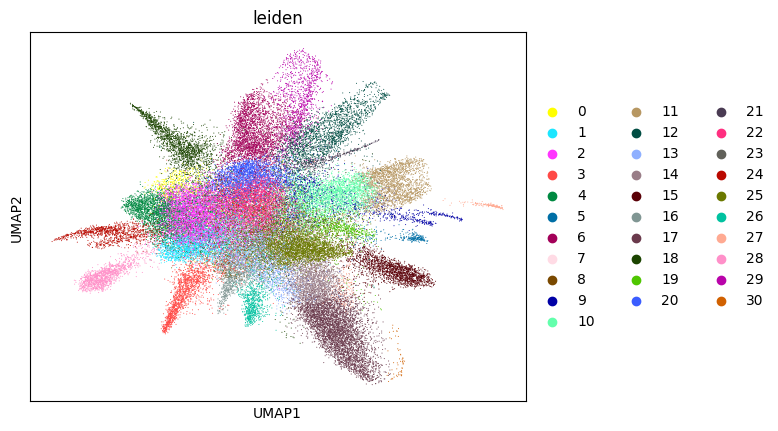

In [14]:
adata_sc = su.singlecellanalysis(adata_sc,resolution=2)

Here, we start performing iterations. Note that this function can be time-consuming.

100%|██████████| 56867/56867 [01:06<00:00, 850.45it/s]


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


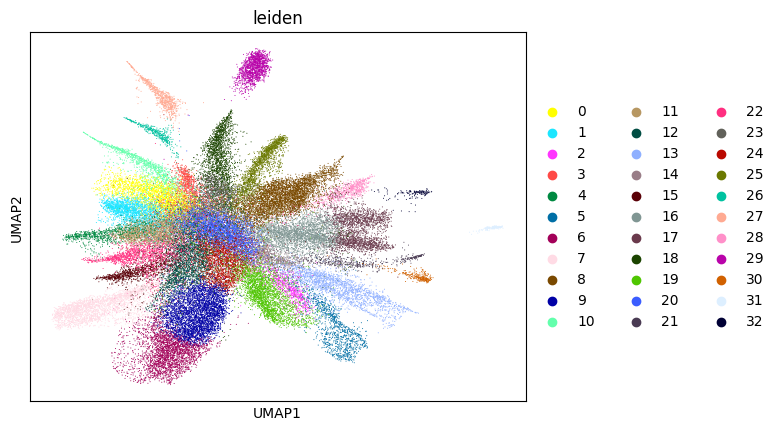

0.42587605351650787 1


100%|██████████| 56867/56867 [01:05<00:00, 871.17it/s] 


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


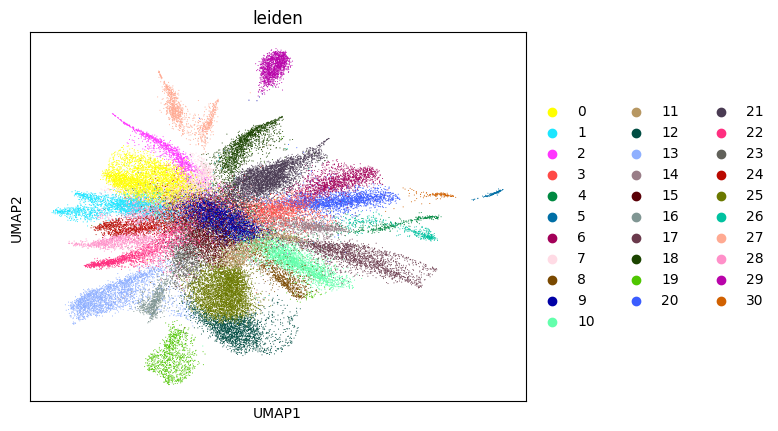

0.6653163073440685 2


100%|██████████| 56867/56867 [01:04<00:00, 877.57it/s]


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


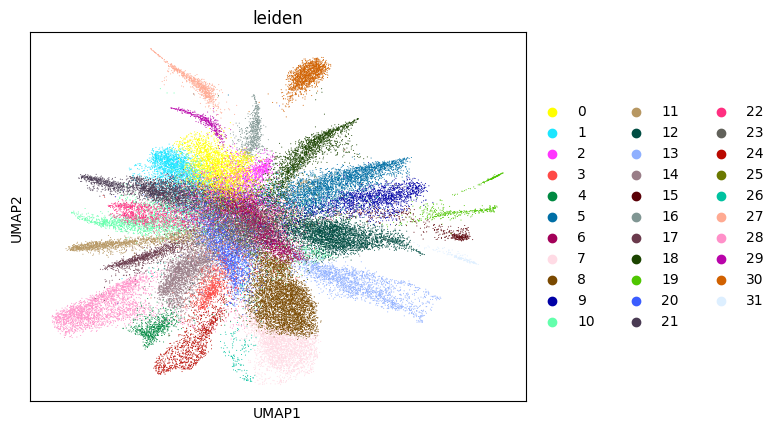

0.692272176364526 3


100%|██████████| 56867/56867 [01:05<00:00, 870.43it/s] 


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


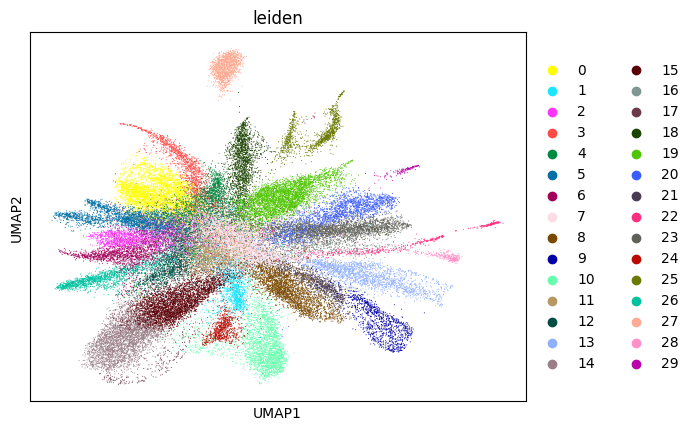

0.7058946412586965 4


100%|██████████| 56867/56867 [01:04<00:00, 879.85it/s] 


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


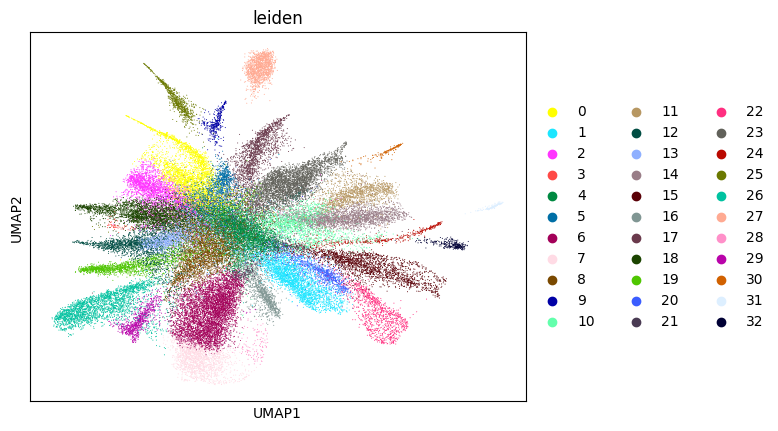

0.7017089650355296 5


100%|██████████| 56867/56867 [01:04<00:00, 880.09it/s]


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


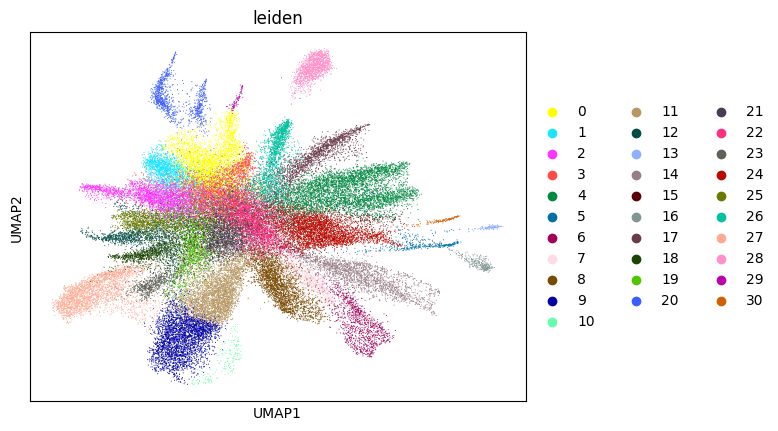

0.6986723859819448 6


In [15]:
su.itering_arragement(adata_sc, adata_raw, adata, so, resolution=2, save_folder = save_path, show = True, keep_previous = False)

Load results here. From this point onward, the SMURF-full workflow differs from the SMURF-lite workflow. The full workflow continues with a deep-learning refinement step for shared spots, whereas the lite workflow uses the non-deep-learning assignment strategy.

In [16]:
adatas_final = sc.read_h5ad(save_path +'adatas.h5ad')

with open(save_path +'cells_final.pkl', 'rb') as file:
    cells_final = pickle.load(file)

with open(save_path +'weights_record.pkl', 'rb') as file:
    weights_record = pickle.load(file)

Here, we generate the following objects:

- `pct_toml_dic`
- `spots_X_dic`
- `celltypes_dic`
- `cells_X_plus_dic`
- `nonzero_indices_dic`
- `nonzero_indices_toml`
- `cells_before_ml`
- `cells_before_ml_x`
- `groups_combined`
- `spots_id_dic`
- `spots_id_dic_prop`

These are used as inputs to the deep-learning model that estimates the final spot-level proportions. Adjust `maximum_cells = 6000` according to your available GPU memory. Start conservatively and increase it only after confirming that the preparation step fits in memory.

If you have millions of cells, this step may take a considerable amount of time. Save these files if you want to restart from the deep-learning preparation stage without repeating earlier computations.


```python
#save files:
import pickle
import gzip

def save_compressed_pickle(data, filename):
    with gzip.GzipFile(filename, 'wb') as f:
        pickle.dump(data, f, protocol=pickle.HIGHEST_PROTOCOL)


save_compressed_pickle(spots_X_dic, save_path + "spots_X_dic.pkl.gz")
save_compressed_pickle(celltypes_dic, save_path + "celltypes_dic.pkl.gz")
save_compressed_pickle(nonzero_indices_dic, save_path + "nonzero_indices_dic.pkl.gz")
save_compressed_pickle(nonzero_indices_toml, save_path + "nonzero_indices_toml.pkl.gz")
save_compressed_pickle(cells_X_plus_dic, save_path + "cells_X_plus_dic.pkl.gz")
save_compressed_pickle(cells_before_ml, save_path + "cells_before_ml.pkl.gz")
save_compressed_pickle(cells_before_ml_x, save_path + "cells_before_ml_x.pkl.gz")
save_compressed_pickle(groups_combined, save_path + "groups_combined.pkl.gz")
save_compressed_pickle(spots_id_dic, save_path + "spots_id_dic.pkl.gz")
save_compressed_pickle(spots_id_dic_prop, save_path + "spots_id_dic_prop.pkl.gz")
save_compressed_pickle(pct_toml_dic, save_path + 'pct_toml_dic.pkl.gz')


#load files:
# Define a function to load compressed pickles
def load_compressed_pickle(filename):
    with gzip.GzipFile(filename, 'rb') as f:
        return pickle.load(f)

weight_to_celltype = load_compressed_pickle(save_path + 'weight_to_celltype.pkl.gz')
cells_before_ml = load_compressed_pickle(save_path + 'cells_before_ml.pkl.gz')
groups_combined = load_compressed_pickle(save_path + 'groups_combined.pkl.gz')
pct_toml_dic = load_compressed_pickle(save_path + 'pct_toml_dic.pkl.gz')
nonzero_indices_dic = load_compressed_pickle(save_path + 'nonzero_indices_dic.pkl.gz')
nonzero_indices_toml = load_compressed_pickle(save_path + 'nonzero_indices_toml.pkl.gz')
```


In [17]:
pct_toml_dic, spots_X_dic, celltypes_dic, cells_X_plus_dic, nonzero_indices_dic, nonzero_indices_toml, cells_before_ml, cells_before_ml_x, groups_combined, spots_id_dic,spots_id_dic_prop = su.make_preparation(cells_final, 
                                                                                                                so, adatas_final, adata, weights_record, maximum_cells = 6000)

100%|██████████| 1690156/1690156 [03:01<00:00, 9324.97it/s] 


Prepare the computing device for training. A GPU is strongly recommended for practical runtimes in the SMURF-full workflow.

In [18]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

if device.type != "cuda":
    print("Warning: CUDA was not detected. The SMURF-full workflow may be impractically slow on CPU. Use the SMURF-lite tutorial instead if a GPU is not available.")

device(type='cuda')

Start model training here. Save the results immediately after each run. On an NVIDIA GeForce RTX 3090, training one group typically takes about 10 minutes, although runtime depends on group size and hardware.

In [19]:
spot_cell_dic = su.start_optimization(spots_X_dic, celltypes_dic, cells_X_plus_dic, nonzero_indices_toml, device, 
                                      num_epochs=1000, learning_rate=0.1, print_each=100, epsilon=0.00001,)
with open(save_path +'spot_cell_dic.pkl', 'wb') as f:
    pickle.dump(spot_cell_dic, f)

Group 0:
Epoch 1, Loss: 0.3869379758834839
Stopping early at epoch 31 due to minimal loss improvement.
Group 1:
Epoch 1, Loss: 0.5507514476776123
Stopping early at epoch 35 due to minimal loss improvement.
Group 2:
Epoch 1, Loss: 0.5118075609207153
Stopping early at epoch 37 due to minimal loss improvement.
Group 3:
Epoch 1, Loss: 0.45116573572158813
Stopping early at epoch 32 due to minimal loss improvement.
Group 4:
Epoch 1, Loss: 0.389637291431427
Stopping early at epoch 42 due to minimal loss improvement.


Since we are using the filtered version of the data, if you want to recover the full gene set in the final dataset, you can use the following code:

```python
adata1 = sc.read_10x_mtx(data_path + 'binned_outputs/square_002um/filtered_feature_bc_matrix')
adata1 = adata1[so.df[so.df.in_tissue == 1]['barcode']]
weight_to_celltype = su.calculate_weight_to_celltype(adatas_final, adata1, cells_final, so)
adata_sc_final2 = su.get_finaldata(
    adata1,
    adatas_final,
    spot_cell_dic,
    weight_to_celltype,
    cells_before_ml,
    groups_combined,
    pct_toml_dic,
    nonzero_indices_dic,
    spots_X_dic=None,
    nonzero_indices_toml=nonzero_indices_toml,
    cells_before_ml_x=None,
    so=so
)
adata_sc_final2
```

 55%|█████▌    | 12865/23340 [15:59<14:48, 11.79it/s]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

100%|██████████| 23340/23340 [26:47<00:00, 14.52it/s] 


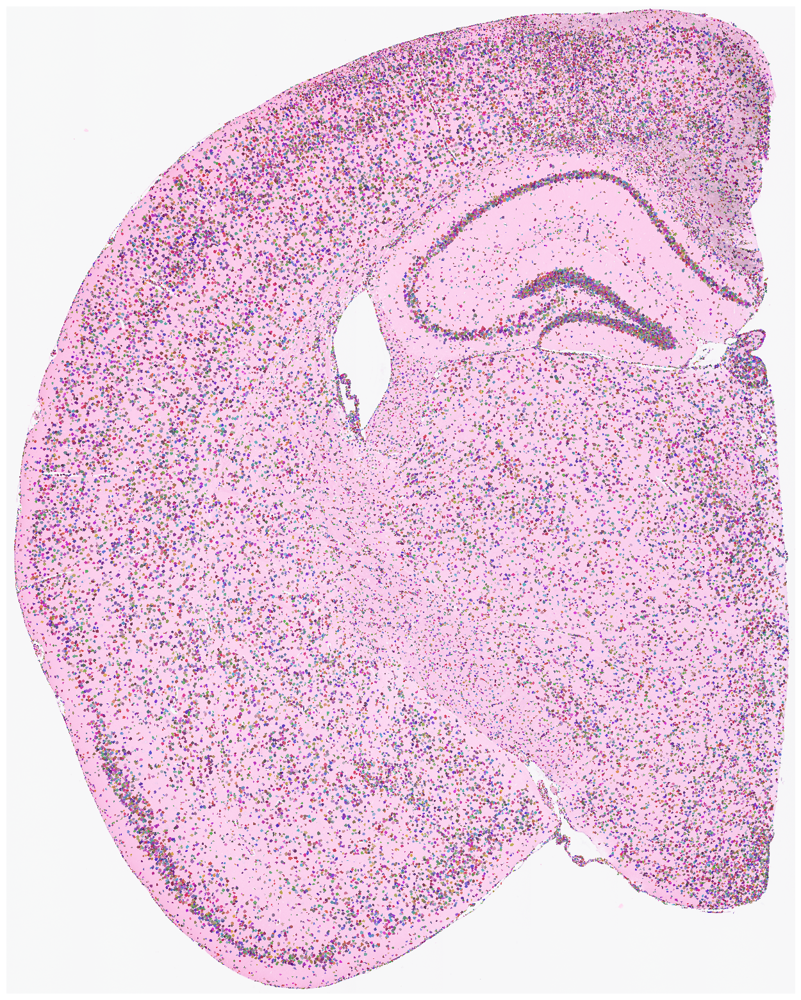

In [20]:
su.make_pixels_cells(so, adata, cells_before_ml, spot_cell_dic, spots_id_dic, spots_id_dic_prop, nonzero_indices_dic)
su.plot_results(so.image_temp(), so.pixels_cells, dpi = 1500, save = save_path + 'final_results.pdf')

Finally, we generate a pixels-to-cell visualization overlaid on the original staining image. Saving this figure can take a long time. Use `save=None` or `save=False` if saving is not needed. High DPI settings also increase runtime; `dpi=1500` is a typical high-resolution setting.

Here, `adata_sc_final.obs` contains five columns:

- `cell_cluster`: cluster assignment from the iterative workflow.
- `cos_simularity`: cosine similarity between each cell’s expression profile and the average expression of its assigned cluster.
- `cell_size`: number of 2 μm spots occupied by the cell.
- `array_row` and `array_col`: absolute spatial coordinates corresponding to the 10x spot layout.

In [21]:
adata_sc_final = su.get_finaldata(adata, adatas_final, spot_cell_dic, weights_record, cells_before_ml, groups_combined, 
                               pct_toml_dic,  nonzero_indices_dic, spots_X_dic, cells_before_ml_x = cells_before_ml_x, so = so)
adata_sc_final

AnnData object with n_obs × n_vars = 56861 × 9970
    obs: 'cell_cluster', 'cos_simularity', 'cell_size', 'array_row', 'array_col', 'n_counts'
    var: 'gene_ids', 'feature_types'
    uns: 'spatial'
    obsm: 'spatial'

In [22]:
with open(save_path + "so.pkl", 'wb') as f:
    pickle.dump(so, f)

adata_sc_final.write(save_path + "adata_sc_final.h5ad")

In [23]:
adata1 = sc.read_10x_mtx(data_path +'binned_outputs/square_002um/filtered_feature_bc_matrix')
adata1 = adata1[so.df[so.df.in_tissue == 1]['barcode']]
weight_to_celltype = su.calculate_weight_to_celltype(adatas_final, adata1, cells_final, so)
adata_sc_final2 = su.get_finaldata(adata1, adatas_final, spot_cell_dic, weight_to_celltype, cells_before_ml, 
                                   groups_combined, pct_toml_dic, nonzero_indices_dic, spots_X_dic = None, 
                                   nonzero_indices_toml = nonzero_indices_toml, cells_before_ml_x = None, so = so)
adata_sc_final2

100%|██████████| 56867/56867 [01:27<00:00, 647.57it/s]


AnnData object with n_obs × n_vars = 56864 × 19059
    obs: 'cell_cluster', 'cos_simularity', 'cell_size', 'array_row', 'array_col', 'n_counts'
    var: 'gene_ids', 'feature_types'
    uns: 'spatial'
    obsm: 'spatial'

In [24]:
adata_sc_final2.write(save_path + "adata_sc_final2.h5ad")